# Chance level C vs I (FCz i Oz, 1000-1500 ms)

## Passos del notebook (dependència de la inicialització compartida)

 > Aquest notebook reutilitza la mateixa inicialització comuna per garantir comparabilitat amb la classificació principal.

1. Executar la inicialització compartida per carregar imports, rutes, constants i funcions bàsiques.
2. Reutilitzar el mateix pipeline de construcció de features (FCz theta + Oz alpha, finestra 1000-1500 ms).
3. Definir el protocol d'estimació de chance level i les seves repeticions/validacions.
4. Executar benchmarks de models simples amb les mateixes particions i convencions de mètriques.
5. Comparar el rendiment observat amb el nivell esperat per atzar i reportar conclusions de robustesa.
6. Deixar resultats en un format alineat amb el notebook de classificació simple per facilitar comparació directa.

### Nota
La inicialització compartida ja està integrada. Queda pendent una fase de deduplicació completa del codi local en aquest notebook.

In [10]:
import nbformat
from pathlib import Path

# Try to find initialization notebook
paths = [
    Path("./00_inicialització.ipynb"),
    Path("./src/notebooks/00_inicialització.ipynb"),
    Path("/content/drive/My Drive/Universitat/TFG/src/notebooks/00_inicialització.ipynb"),
]

nb_path = next((p for p in paths if p.exists()), None)
if not nb_path:
    raise FileNotFoundError(f"00_inicialització.ipynb not found. Colab: mount Google Drive first.")

# Load and execute initialization
with open(nb_path, encoding="utf-8") as f:
    nb = nbformat.read(f, as_version=4)

for cell in nb.cells:
    if cell.cell_type == "code":
        exec(cell.source, globals())

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.linear_model import LogisticRegression

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Entorn: Colab
Directori dades: /content/drive/MyDrive/TFG_Nils_2026/02_Data/01_Preprocessed_epochs
Fitxers trobats: 47


In [11]:
processed_dir = DATA_DIR / "processed"
dataset_path = processed_dir / "c_vs_i_fcz_theta_oz_alpha_stft.npz"

if not dataset_path.exists():
    raise FileNotFoundError(f"No existeix {dataset_path}. Executa abans 01_preprocessament.ipynb.")

dataset = np.load(dataset_path, allow_pickle=True)
X = dataset["X"].astype(np.float32)
y = dataset["y"].astype(np.int8)
y_detail = dataset["y_detail"].astype(str)
subj_list = dataset["subj_list"].astype(str)

ICA_COMPONENTS = int(min(ICA_MAX_COMPONENTS, X.shape[1]))

n_congruent = int(np.sum(y_detail == "Congruent"))
n_pur = int(np.sum(y_detail == "Incongruent_Pur"))
n_mixt = int(np.sum(y_detail == "Incongruent_Mixt"))
n_incongruent = int(n_pur + n_mixt)

print(f"Dataset carregat de: {dataset_path}")
print(f"Mostres totals: {len(y)}")
print(f"Congruent (0): {(y == 0).sum()} | Incongruent (1): {(y == 1).sum()}")
print(f"Subjectes inclosos: {len(np.unique(subj_list))}")
print(f"Matriu de caracteristiques: {X.shape}")
print(f"Components ICA maxims: {ICA_COMPONENTS}")
print(f"Counts -> C: {n_congruent} | I: {n_incongruent} | I pur: {n_pur} | I mixt: {n_mixt}")

Mostres totals: 22860
Congruent (0): 8471 | Incongruent (1): 14389
Subjectes inclosos: 47
Matriu de caracteristiques: (22860, 216)
Components ICA maxims: 20
Counts -> C: 8471 | I: 14389 | I pur: 6075 | I mixt: 8314


## EDA conductual i dominància ocular (notebook de resultats)

Aquest bloc resumeix codis conductuals tipus CRP/CGP/IPR/IPG/IM i quantifica la dominància ocular en trials incongruents purs, tant per subjecte com globalment.

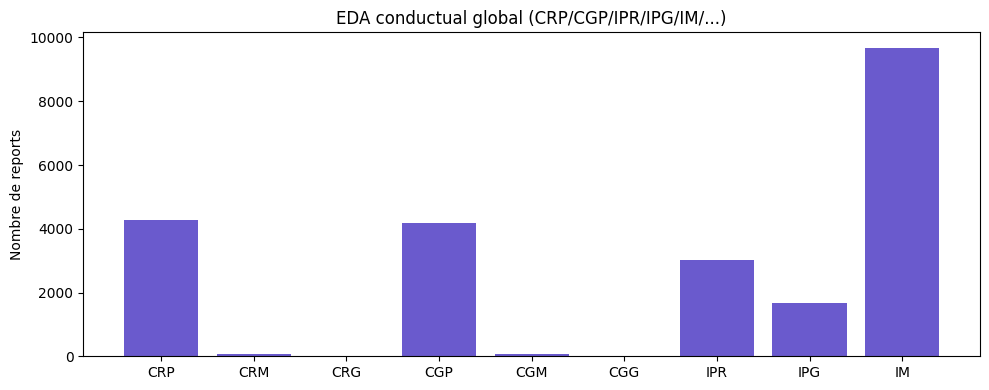

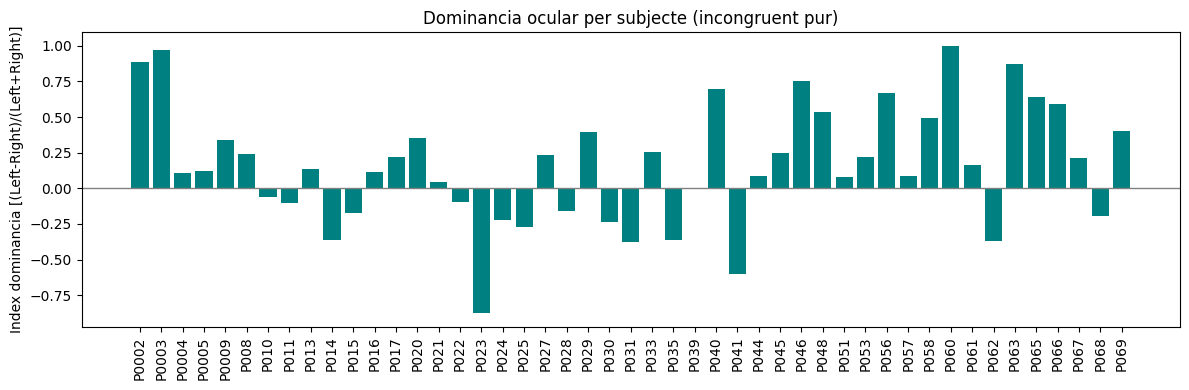

Resum conductual global:
  CRP :  4276
  CRM :    73
  CRG :    22
  CGP :  4195
  CGM :    77
  CGG :    17
  IPR :  3010
  IPG :  1679
  IM  :  9678

Dominancia ocular global (incongruent pur):
  Left-eye coherent : 2796
  Right-eye coherent: 1893
  Index global      : 0.193  (positiu = tendencia ull esquerre)


In [14]:
# EDA conductual basat en els events preprocesats (event_1..event_12)
EVENT_TO_LABEL = {
    1: "CRP",
    2: "CGP",
    3: "IPR",
    4: "IPR",
    5: "IPG",
    6: "IPG",
    7: "IM",
    8: "IM",
    9: "CRG",
    10: "CGG",
    11: "CRM",
    12: "CGM",
}

labels_order = ["CRP", "CRM", "CRG", "CGP", "CGM", "CGG", "IPR", "IPG", "IM"]
label_counts = {k: 0 for k in labels_order}

eye_rows = []
for fif_path in DATA_FILES:
    ep_meta = mne.read_epochs(fif_path, preload=False, verbose=False)
    ev = ep_meta.events[:, 2]

    for code in ev:
        if code in EVENT_TO_LABEL:
            label_counts[EVENT_TO_LABEL[code]] += 1

    left_eye = int(np.sum(np.isin(ev, [3, 6])))
    right_eye = int(np.sum(np.isin(ev, [4, 5])))
    total_pure = left_eye + right_eye
    dominance_idx = (left_eye - right_eye) / total_pure if total_pure > 0 else np.nan

    eye_rows.append(
        {
            "subjecte": fif_path.stem,
            "left_eye": left_eye,
            "right_eye": right_eye,
            "total_pure": total_pure,
            "dominance_idx": dominance_idx,
        }
    )

x = np.arange(len(labels_order))
vals = [label_counts[k] for k in labels_order]

plt.figure(figsize=(10, 4))
plt.bar(x, vals, color="slateblue")
plt.xticks(x, labels_order)
plt.ylabel("Nombre de reports")
plt.title("EDA conductual global (CRP/CGP/IPR/IPG/IM/...)")
plt.tight_layout()
plt.show()

subjects_sorted = sorted(eye_rows, key=lambda r: r["subjecte"])
subj_names = [r["subjecte"] for r in subjects_sorted]
idx_vals = [r["dominance_idx"] for r in subjects_sorted]

plt.figure(figsize=(12, 4))
plt.axhline(0, color="gray", linewidth=1)
plt.bar(subj_names, idx_vals, color="teal")
plt.ylabel("Index dominancia [(Left-Right)/(Left+Right)]")
plt.title("Dominancia ocular per subjecte (incongruent pur)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

left_global = int(np.sum([r["left_eye"] for r in eye_rows]))
right_global = int(np.sum([r["right_eye"] for r in eye_rows]))
pure_global = left_global + right_global
global_idx = (left_global - right_global) / pure_global if pure_global > 0 else np.nan

print("Resum conductual global:")
for k in labels_order:
    print(f"  {k:4s}: {label_counts[k]:5d}")

print("\nDominància ocular global (incongruent pur):")
print(f"  Left-eye coherent : {left_global}")
print(f"  Right-eye coherent: {right_global}")
print(f"  Index global      : {global_idx:.3f}  (positiu = tendència ull esquerre)")

Atipics detectats: 1723 de 22860; (7.54%)
Nota: no els eliminem en aquesta versió.


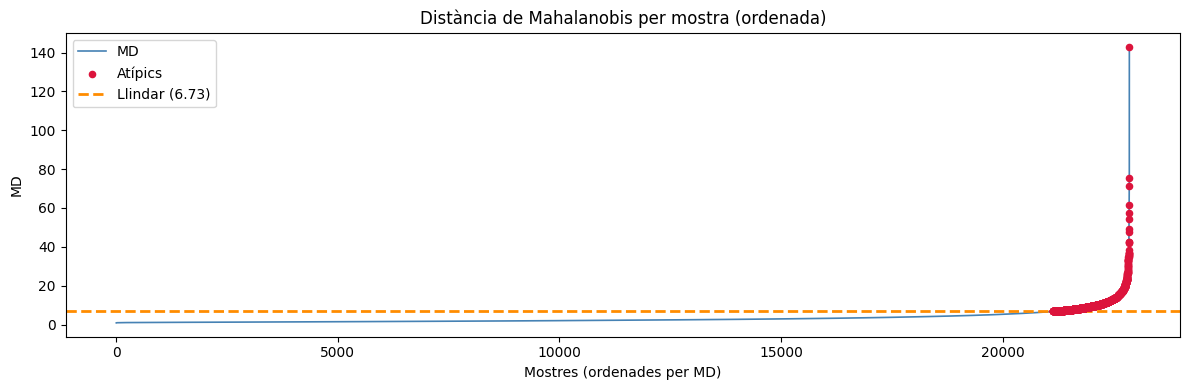

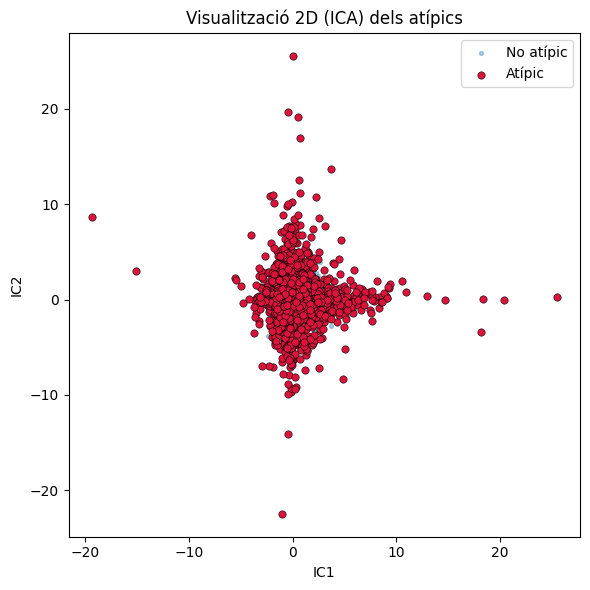

In [6]:
def mahalanobis_outliers(data, alpha=0.999):
    scaler = StandardScaler()
    data_scaled = scaler.fit_transform(data)

    ica_m = FastICA(
        n_components=min(ICA_COMPONENTS, data_scaled.shape[1]),
        random_state=42,
        whiten="unit-variance",
        max_iter=1000,
        tol=0.0005,
    )
    data_ica = ica_m.fit_transform(data_scaled)

    mean = np.mean(data_ica, axis=0)
    cov = np.cov(data_ica, rowvar=False)
    inv_cov = np.linalg.pinv(cov)

    diff = data_ica - mean
    md2 = np.einsum("ij,jk,ik->i", diff, inv_cov, diff)
    md = np.sqrt(np.clip(md2, 0, None))

    threshold = np.sqrt(chi2.ppf(alpha, df=data_ica.shape[1]))
    return md, md > threshold, threshold, data_ica


md_values, is_outlier, md_threshold, data_ica = mahalanobis_outliers(X)
print(f"Atipics detectats: {is_outlier.sum()} de {len(X)}; ({is_outlier.mean() * 100:.2f}%)")
print("Nota: no els eliminem en aquesta versió.")

# --- Plot 1: distància de Mahalanobis ordenada ---
order = np.argsort(md_values)
md_sorted = md_values[order]
out_sorted = is_outlier[order]

plt.figure(figsize=(12, 4))
plt.plot(md_sorted, color="steelblue", lw=1.2, label="MD")
plt.scatter(
    np.where(out_sorted)[0],
    md_sorted[out_sorted],
    color="crimson",
    s=20,
    label="Atípics",
    zorder=3,
)
plt.axhline(md_threshold, color="darkorange", ls="--", lw=2, label=f"Llindar ({md_threshold:.2f})")
plt.title("Distància de Mahalanobis per mostra (ordenada)")
plt.xlabel("Mostres (ordenades per MD)")
plt.ylabel("MD")
plt.legend()
plt.tight_layout()
plt.show()

# --- Plot 2: projecció ICA 2D amb atípics ---
plt.figure(figsize=(6, 6))
plt.scatter(
    data_ica[~is_outlier, 0],
    data_ica[~is_outlier, 1],
    s=8,
    alpha=0.35,
    label="No atípic",
)
plt.scatter(
    data_ica[is_outlier, 0],
    data_ica[is_outlier, 1],
    s=28,
    c="crimson",
    edgecolors="k",
    linewidths=0.4,
    label="Atípic",
)
plt.title("Visualització 2D (ICA) dels atípics")
plt.xlabel("IC1")
plt.ylabel("IC2")
plt.legend()
plt.tight_layout()
plt.show()

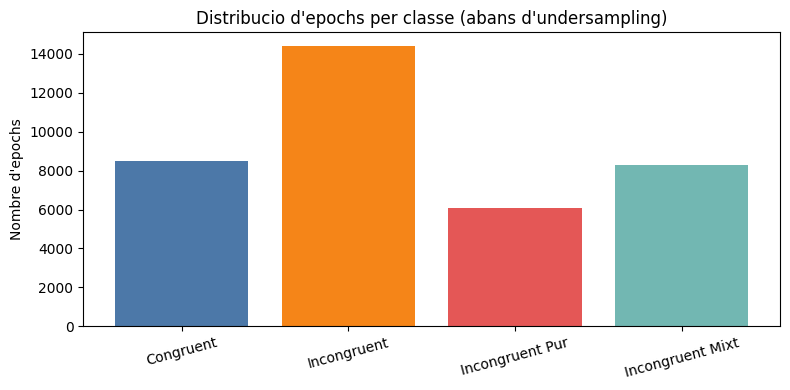

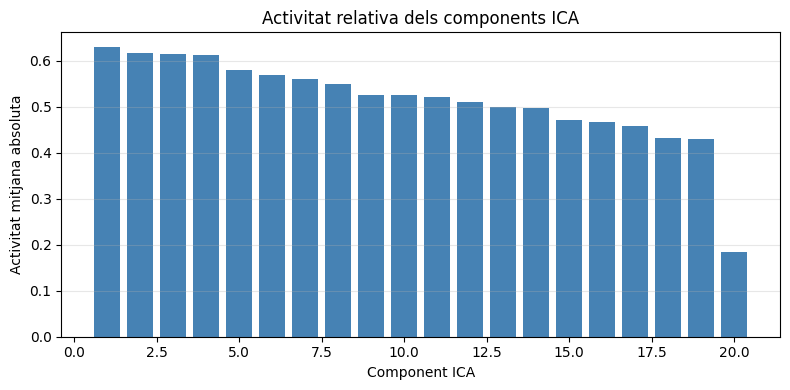

Components ICA disponibles: 20
Suggeriment automatic de components ICA: 19
Si vols forcar-ho manualment: ICA_COMPONENTS_SELECTED = <valor>


In [ ]:
def count_4classes(labels):
    c = int(np.sum(labels == "Congruent"))
    i_pur = int(np.sum(labels == "Incongruent_Pur"))
    i_mixt = int(np.sum(labels == "Incongruent_Mixt"))
    i_total = int(i_pur + i_mixt)
    return {
        "Congruent": c,
        "Incongruent": i_total,
        "Incongruent_Pur": i_pur,
        "Incongruent_Mixt": i_mixt,
    }


# La visualitzacio principal de desbalanc de classes ara es fa al notebook 01_exploracio_dades.
# Aqui mantenim només el diagnostic per decidir el nombre de components ICA.
X_ica_source = X
X_scaled = StandardScaler().fit_transform(X_ica_source)
n_components = min(ICA_COMPONENTS, X_scaled.shape[0] - 1, X_scaled.shape[1])

ica_diag = FastICA(
    n_components=n_components,
    random_state=42,
    whiten="unit-variance",
    max_iter=1000,
    tol=0.0005,
)
sources = ica_diag.fit_transform(X_scaled)
component_activity = np.mean(np.abs(sources), axis=0)
order = np.argsort(component_activity)[::-1]
activity_sorted = component_activity[order]

plt.figure(figsize=(8, 4))
plt.bar(np.arange(1, n_components + 1), activity_sorted, color="steelblue")
plt.xlabel("Component ICA")
plt.ylabel("Activitat mitjana absoluta")
plt.title("Activitat relativa dels components ICA")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

activity_ratio = activity_sorted / activity_sorted[0]
ICA_COMPONENTS_SELECTED = int(np.clip(np.sum(activity_ratio >= 0.60), 2, n_components))

print(f"Components ICA disponibles: {n_components}")
print(f"Suggeriment automatic de components ICA: {ICA_COMPONENTS_SELECTED}")
print("Si vols forcar-ho manualment: ICA_COMPONENTS_SELECTED = <valor>")

P0002 | epochs=384 | train 230->172 | ICA=19 | VAL F1=0.549 | TEST F1=0.509 | TEST ACC=0.532
P0003 | epochs=501 | train 300->228 | ICA=19 | VAL F1=0.597 | TEST F1=0.591 | TEST ACC=0.614
P0004 | epochs=586 | train 351->260 | ICA=19 | VAL F1=0.490 | TEST F1=0.558 | TEST ACC=0.576
P0005 | epochs=456 | train 273->200 | ICA=19 | VAL F1=0.480 | TEST F1=0.479 | TEST ACC=0.489
P0009 | epochs=581 | train 348->268 | ICA=19 | VAL F1=0.555 | TEST F1=0.492 | TEST ACC=0.530
P008 | epochs=248 | train 148->108 | ICA=19 | VAL F1=0.480 | TEST F1=0.495 | TEST ACC=0.500
P010 | epochs=623 | train 373->296 | ICA=19 | VAL F1=0.444 | TEST F1=0.552 | TEST ACC=0.552
P011 | epochs=431 | train 258->146 | ICA=19 | VAL F1=0.549 | TEST F1=0.436 | TEST ACC=0.517
P013 | epochs=577 | train 345->270 | ICA=19 | VAL F1=0.450 | TEST F1=0.495 | TEST ACC=0.500
P014 | epochs=406 | train 243->152 | ICA=19 | VAL F1=0.463 | TEST F1=0.412 | TEST ACC=0.427
P015 | epochs=405 | train 243->160 | ICA=19 | VAL F1=0.582 | TEST F1=0.609 

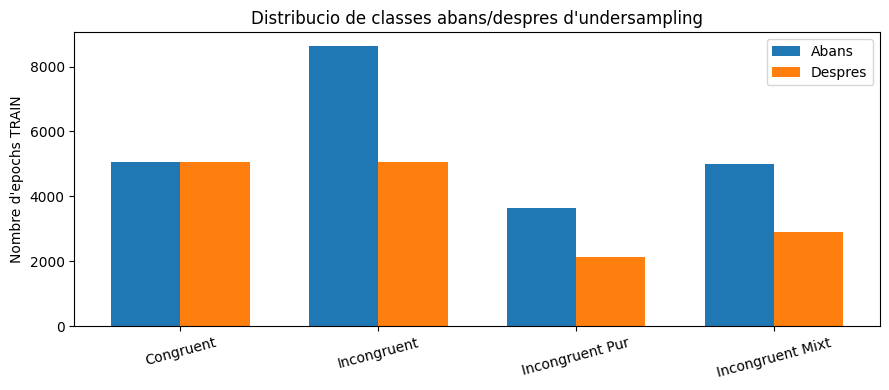

In [13]:
from time import perf_counter


def undersample_binary(X_in, y_in, random_state=42):
    classes, counts = np.unique(y_in, return_counts=True)
    if len(classes) < 2:
        return X_in, y_in, np.arange(len(y_in))

    n_min = counts.min()
    rng = np.random.default_rng(random_state)
    selected_idx = []
    for cls in classes:
        cls_idx = np.where(y_in == cls)[0]
        sampled = rng.choice(cls_idx, size=n_min, replace=False)
        selected_idx.extend(sampled.tolist())

    selected_idx = np.array(selected_idx)
    rng.shuffle(selected_idx)
    return X_in[selected_idx], y_in[selected_idx], selected_idx


subjects = np.unique(subj_list)
subject_results = []

train_before_detail = []
train_after_detail = []

for subj_i, subj in enumerate(subjects):
    idx = np.where(subj_list == subj)[0]
    X_subj = X[idx]
    y_subj = y[idx]
    y_detail_subj = y_detail[idx]

    if len(np.unique(y_subj)) < 2 or len(y_subj) < 30:
        print(f"{subj}: no te suficients epochs per entrenar/testar de forma estable. S'omet.")
        continue

    try:
        X_train, X_test, y_train, y_test, detail_train, detail_test = train_test_split(
            X_subj,
            y_subj,
            y_detail_subj,
            test_size=0.2,
            random_state=42,
            stratify=y_subj,
        )

        X_train, X_val, y_train, y_val, detail_train, detail_val = train_test_split(
            X_train,
            y_train,
            detail_train,
            test_size=0.25,
            random_state=42,
            stratify=y_train,
        )
    except ValueError:
        print(f"{subj}: split estratificat impossible per manca de mostres per classe. S'omet.")
        continue

    train_before_detail.extend(detail_train.tolist())

    X_train_us, y_train_us, us_idx = undersample_binary(X_train, y_train, random_state=42 + subj_i)
    detail_train_us = detail_train[us_idx]
    train_after_detail.extend(detail_train_us.tolist())

    n_components_subj = min(ICA_COMPONENTS_SELECTED, X_train_us.shape[0] - 1, X_train_us.shape[1])
    if n_components_subj < 2:
        print(f"{subj}: no te prou mostres despres d'undersampling per ICA. S'omet.")
        continue

    model = Pipeline(
        [
            ("scaler", StandardScaler()),
            (
                "ica",
                FastICA(
                    n_components=n_components_subj,
                    random_state=42,
                    whiten="unit-variance",
                    max_iter=1000,
                    tol=0.0005,
                ),
            ),
            ("clf", LogisticRegression(max_iter=2000, random_state=42, class_weight="balanced")),
        ]
    )

    t0 = perf_counter()
    model.fit(X_train_us, y_train_us)
    elapsed = perf_counter() - t0

    y_val_pred = model.predict(X_val)
    y_test_pred = model.predict(X_test)

    res = {
        "subjecte": subj,
        "n_epochs": int(len(y_subj)),
        "n_train_before": int(len(y_train)),
        "n_train_after": int(len(y_train_us)),
        "ica_components": int(n_components_subj),
        "f1_val": float(f1_score(y_val, y_val_pred, average="macro")),
        "acc_val": float(accuracy_score(y_val, y_val_pred)),
        "f1_test": float(f1_score(y_test, y_test_pred, average="macro")),
        "acc_test": float(accuracy_score(y_test, y_test_pred)),
        "elapsed_s": float(elapsed),
    }
    subject_results.append(res)

    print(
        f"{subj} | epochs={res['n_epochs']} | train {res['n_train_before']}->{res['n_train_after']} "
        f"| ICA={res['ica_components']} | VAL F1={res['f1_val']:.3f} "
        f"| TEST F1={res['f1_test']:.3f} | TEST ACC={res['acc_test']:.3f}"
    )

print("\nResum global (model diferent per individu):")
if subject_results:
    mean_f1_test = np.mean([r["f1_test"] for r in subject_results])
    mean_acc_test = np.mean([r["acc_test"] for r in subject_results])
    print(f"Subjectes entrenats: {len(subject_results)}")
    print(f"Mitjana TEST F1 macro: {mean_f1_test:.3f}")
    print(f"Mitjana TEST Accuracy: {mean_acc_test:.3f}")
else:
    print("No s'ha pogut entrenar cap subjecte amb els criteris actuals.")

# Plot abans/despres d'undersampling (sobre TRAIN agregat de tots els subjectes)
counts_before = count_4classes(np.array(train_before_detail, dtype=object))
counts_after = count_4classes(np.array(train_after_detail, dtype=object))

labels = list(counts_before.keys())
x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(9, 4))
plt.bar(x - width / 2, [counts_before[k] for k in labels], width, label="Abans")
plt.bar(x + width / 2, [counts_after[k] for k in labels], width, label="Despres")
plt.xticks(x, labels, rotation=15)
plt.ylabel("Nombre d'epochs TRAIN")
plt.title("Distribucio de classes abans/despres d'undersampling")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
print("Seccio antiga de comparatives de models desactivada.")
print("Ara el model s'entrena per subjecte a la cel.la principal d'entrenament.")

Resultats CV C vs I amb LDA:
F1 macro -> Mitjana: 0.524 | Desviacio: 0.017
Accuracy -> Mitjana: 0.598 | Desviacio: 0.020
Scores F1 macro per fold: [0.502 0.533 0.551 0.523 0.51 ]
Scores Accuracy per fold: [0.596 0.599 0.603 0.565 0.629]
Temps CV: 0.35 s

Detall ultim fold de CV (per comprovar biaix de classe):
Confusion matrix [files=true, columnes=pred]:
[[ 223  917]
 [ 302 1843]]
Classification report:
                 precision    recall  f1-score   support

  Congruent (C)      0.425     0.196     0.268      1140
Incongruent (I)      0.668     0.859     0.751      2145

       accuracy                          0.629      3285
      macro avg      0.546     0.527     0.510      3285
   weighted avg      0.583     0.629     0.584      3285


Resultat en TEST FINAL independent (subjectes no vistos):
Confusion matrix [files=true, columnes=pred]:
[[ 718 1313]
 [ 880 2483]]
Classification report:
                 precision    recall  f1-score   support

  Congruent (C)      0.449     0.3

In [ ]:
print("Seccio antiga de comparatives de models desactivada.")
print("Ara el model s'entrena per subjecte a la cel.la principal d'entrenament.")

Resultats CV C vs I amb Random Forest:
F1 macro -> Mitjana: 0.499 | Desviacio: 0.009
Accuracy -> Mitjana: 0.606 | Desviacio: 0.012
Scores F1 macro per fold: [0.493 0.499 0.505 0.513 0.487]
Scores Accuracy per fold: [0.598 0.606 0.604 0.594 0.629]
Temps CV: 45.30 s

Detall ultim fold de CV (per comprovar biaix de classe):
Confusion matrix [files=true, columnes=pred]:
[[ 167  973]
 [ 250 1895]]
Classification report:
                 precision    recall  f1-score   support

  Congruent (C)      0.400     0.146     0.215      1140
Incongruent (I)      0.661     0.883     0.756      2145

       accuracy                          0.628      3285
      macro avg      0.531     0.515     0.485      3285
   weighted avg      0.570     0.628     0.568      3285


Resultat en TEST FINAL independent (subjectes no vistos):
Confusion matrix [files=true, columnes=pred]:
[[ 430 1601]
 [ 550 2813]]
Classification report:
                 precision    recall  f1-score   support

  Congruent (C)      0.

In [ ]:
print("Instal.lacio XGBoost/LightGBM no necessaria en el nou flux.")

In [ ]:
print("Seccio antiga de comparatives de models desactivada.")
print("Ara el model s'entrena per subjecte a la cel.la principal d'entrenament.")

Resultats CV C vs I amb XGBoost:
F1 macro -> Mitjana: 0.445 | Desviacio: 0.021
Accuracy -> Mitjana: 0.628 | Desviacio: 0.011
Scores F1 macro per fold: [0.44  0.42  0.474 0.466 0.424]
Scores Accuracy per fold: [0.631 0.622 0.627 0.614 0.646]
Temps CV: 1.97 s

Detall ultim fold de CV (per comprovar biaix de classe):
Confusion matrix [files=true, columnes=pred]:
[[  42 1098]
 [  65 2080]]
Classification report:
                 precision    recall  f1-score   support

  Congruent (C)      0.393     0.037     0.067      1140
Incongruent (I)      0.654     0.970     0.782      2145

       accuracy                          0.646      3285
      macro avg      0.524     0.503     0.424      3285
   weighted avg      0.564     0.646     0.534      3285


Resultat en TEST FINAL independent (subjectes no vistos):
Confusion matrix [files=true, columnes=pred]:
[[ 180 1851]
 [ 159 3204]]
Classification report:
                 precision    recall  f1-score   support

  Congruent (C)      0.531    

In [ ]:
print("Seccio antiga de comparatives de models desactivada.")
print("Ara el model s'entrena per subjecte a la cel.la principal d'entrenament.")

Resultats CV C vs I amb LightGBM:
F1 macro -> Mitjana: 0.516 | Desviacio: 0.007
Accuracy -> Mitjana: 0.544 | Desviacio: 0.012
Scores F1 macro per fold: [0.512 0.513 0.53  0.512 0.513]
Scores Accuracy per fold: [0.536 0.536 0.555 0.532 0.562]
Temps CV: 5.73 s


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



Detall ultim fold de CV (per comprovar biaix de classe):
Confusion matrix [files=true, columnes=pred]:
[[ 401  739]
 [ 699 1446]]
Classification report:
                 precision    recall  f1-score   support

  Congruent (C)      0.365     0.352     0.358      1140
Incongruent (I)      0.662     0.674     0.668      2145

       accuracy                          0.562      3285
      macro avg      0.513     0.513     0.513      3285
   weighted avg      0.559     0.562     0.560      3285


Resultat en TEST FINAL independent (subjectes no vistos):
Confusion matrix [files=true, columnes=pred]:
[[ 913 1118]
 [1340 2023]]
Classification report:
                 precision    recall  f1-score   support

  Congruent (C)      0.405     0.450     0.426      2031
Incongruent (I)      0.644     0.602     0.622      3363

       accuracy                          0.544      5394
      macro avg      0.525     0.526     0.524      5394
   weighted avg      0.554     0.544     0.548      5394



/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [ ]:
print("Comparativa antiga desactivada.")
print("Consulta els resultats per subjecte de la cel.la d'entrenament principal.")

Comparativa CV (F1 macro | Accuracy):
LR: 0.524 | 0.594
LDA: 0.524 | 0.598
RF: 0.499 | 0.606
XGBoost: 0.445 | 0.628
LightGBM: 0.516 | 0.544


# Flux actual

Aquesta part del notebook queda simplificada:
- Split per epochs (train/val/test) dins de cada subjecte.
- Un model ICA + LR entrenat per cada individu.
- Undersampling aplicat al TRAIN de cada individu.
- Plots de distribucio de classes i activitat de components ICA.

No es fa la comparativa antiga de components ICA ni la bateria multi-model.

In [ ]:
print("Seccio antiga de comparativa de components ICA desactivada.")
print("El nombre de components es suggereix automaticament al plot ICA.")

ICA components disponibles: 20
Preparat: ICA 5/10/15/20 + NO ICA final.


In [ ]:
print("Seccio antiga de ranking global desactivada.")
print("Ara els resultats es mostren per subjecte a la cel.la principal d'entrenament.")


Configuració: PCA 0.700
  LR | CV F1=0.524+/-0.015 | CV ACC=0.600+/-0.024 | TEST F1=0.544 | TEST ACC=0.595 | F1_C=0.391 | F1_I=0.697 | F1_C*F1_I=0.272
 LDA | CV F1=0.522+/-0.019 | CV ACC=0.603+/-0.023 | TEST F1=0.540 | TEST ACC=0.595 | F1_C=0.380 | F1_I=0.699 | F1_C*F1_I=0.266
  RF | CV F1=0.517+/-0.006 | CV ACC=0.579+/-0.014 | TEST F1=0.517 | TEST ACC=0.568 | F1_C=0.362 | F1_I=0.673 | F1_C*F1_I=0.243
 XGB | CV F1=0.523+/-0.006 | CV ACC=0.553+/-0.005 | TEST F1=0.544 | TEST ACC=0.566 | F1_C=0.445 | F1_I=0.643 | F1_C*F1_I=0.286


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LGBM | CV F1=0.514+/-0.006 | CV ACC=0.533+/-0.005 | TEST F1=0.524 | TEST ACC=0.537 | F1_C=0.445 | F1_I=0.603 | F1_C*F1_I=0.268

Configuració: PCA 0.800
  LR | CV F1=0.522+/-0.015 | CV ACC=0.598+/-0.022 | TEST F1=0.546 | TEST ACC=0.593 | F1_C=0.398 | F1_I=0.693 | F1_C*F1_I=0.276
 LDA | CV F1=0.520+/-0.018 | CV ACC=0.600+/-0.021 | TEST F1=0.544 | TEST ACC=0.596 | F1_C=0.389 | F1_I=0.698 | F1_C*F1_I=0.272
  RF | CV F1=0.507+/-0.006 | CV ACC=0.585+/-0.016 | TEST F1=0.513 | TEST ACC=0.577 | F1_C=0.336 | F1_I=0.690 | F1_C*F1_I=0.232
 XGB | CV F1=0.521+/-0.009 | CV ACC=0.554+/-0.010 | TEST F1=0.528 | TEST ACC=0.552 | F1_C=0.421 | F1_I=0.634 | F1_C*F1_I=0.267


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LGBM | CV F1=0.516+/-0.007 | CV ACC=0.544+/-0.012 | TEST F1=0.524 | TEST ACC=0.544 | F1_C=0.426 | F1_I=0.622 | F1_C*F1_I=0.265

Configuració: PCA 0.900
  LR | CV F1=0.523+/-0.017 | CV ACC=0.598+/-0.022 | TEST F1=0.544 | TEST ACC=0.592 | F1_C=0.397 | F1_I=0.692 | F1_C*F1_I=0.275
 LDA | CV F1=0.522+/-0.017 | CV ACC=0.600+/-0.022 | TEST F1=0.545 | TEST ACC=0.597 | F1_C=0.392 | F1_I=0.699 | F1_C*F1_I=0.274
  RF | CV F1=0.500+/-0.010 | CV ACC=0.583+/-0.015 | TEST F1=0.517 | TEST ACC=0.585 | F1_C=0.335 | F1_I=0.699 | F1_C*F1_I=0.234
 XGB | CV F1=0.522+/-0.008 | CV ACC=0.555+/-0.014 | TEST F1=0.525 | TEST ACC=0.549 | F1_C=0.418 | F1_I=0.631 | F1_C*F1_I=0.264


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


... (2 outputs left out)

LGBM | CV F1=0.515+/-0.011 | CV ACC=0.553+/-0.016 | TEST F1=0.527 | TEST ACC=0.558 | F1_C=0.406 | F1_I=0.648 | F1_C*F1_I=0.263

Configuració: PCA 0.999
  LR | CV F1=0.522+/-0.011 | CV ACC=0.592+/-0.021 | TEST F1=0.543 | TEST ACC=0.589 | F1_C=0.397 | F1_I=0.688 | F1_C*F1_I=0.273
 LDA | CV F1=0.521+/-0.013 | CV ACC=0.596+/-0.023 | TEST F1=0.547 | TEST ACC=0.598 | F1_C=0.395 | F1_I=0.699 | F1_C*F1_I=0.276
  RF | CV F1=0.491+/-0.016 | CV ACC=0.616+/-0.010 | TEST F1=0.499 | TEST ACC=0.611 | F1_C=0.262 | F1_I=0.736 | F1_C*F1_I=0.193
 XGB | CV F1=0.518+/-0.007 | CV ACC=0.558+/-0.014 | TEST F1=0.539 | TEST ACC=0.571 | F1_C=0.419 | F1_I=0.660 | F1_C*F1_I=0.276


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LGBM | CV F1=0.514+/-0.004 | CV ACC=0.556+/-0.014 | TEST F1=0.525 | TEST ACC=0.560 | F1_C=0.394 | F1_I=0.655 | F1_C*F1_I=0.258

Configuració: NO PCA
  LR | CV F1=0.518+/-0.011 | CV ACC=0.584+/-0.017 | TEST F1=0.530 | TEST ACC=0.574 | F1_C=0.386 | F1_I=0.674 | F1_C*F1_I=0.260
 LDA | CV F1=0.521+/-0.007 | CV ACC=0.569+/-0.011 | TEST F1=0.529 | TEST ACC=0.562 | F1_C=0.405 | F1_I=0.653 | F1_C*F1_I=0.265
  RF | CV F1=0.489+/-0.014 | CV ACC=0.614+/-0.010 | TEST F1=0.491 | TEST ACC=0.604 | F1_C=0.251 | F1_I=0.731 | F1_C*F1_I=0.184
 XGB | CV F1=0.523+/-0.007 | CV ACC=0.551+/-0.014 | TEST F1=0.530 | TEST ACC=0.548 | F1_C=0.438 | F1_I=0.622 | F1_C*F1_I=0.273
LGBM | CV F1=0.516+/-0.008 | CV ACC=0.554+/-0.011 | TEST F1=0.527 | TEST ACC=0.553 | F1_C=0.417 | F1_I=0.637 | F1_C*F1_I=0.266

##################################################################################################################################
RÀNQUING GLOBAL (ordenat per TEST F1 macro i despres PRODUCTE F1)
##################

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
